# Clustering Antarctic Penguin Species

Completed as a [DataCamp project](https://app.datacamp.com/learn/projects/1809). This notebook contains my implementation of the guided challenge.


## Dataset and objective

Explore groups in 332 penguin records using unsupervised learning. The supplied dataset contains four physical measurements—culmen length, culmen depth, flipper length, and body mass—plus sex. It does not include species labels.

The source project credits Dr. Kristen Gorman and Palmer Station, Antarctica LTER for collecting and making the data available.

The workflow encodes sex, standardizes the features, compares inertia for 1–9 clusters, fits a six-cluster K-means model, and summarizes each cluster in the original measurement units. The clusters are exploratory groups, not verified species classifications.


In [1]:
# Import Required Packages
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Loading and examining the dataset
penguins_df = pd.read_csv("penguins.csv")
penguins_df.info()
penguins_df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 332 entries, 0 to 331
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   332 non-null    float64
 1   culmen_depth_mm    332 non-null    float64
 2   flipper_length_mm  332 non-null    float64
 3   body_mass_g        332 non-null    float64
 4   sex                332 non-null    object 
dtypes: float64(4), object(1)
memory usage: 13.1+ KB


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,36.7,19.3,193.0,3450.0,FEMALE
4,39.3,20.6,190.0,3650.0,MALE


## 1. Encode and standardize the features


In [2]:
penguins_preprocessed = pd.get_dummies(penguins_df,columns = ["sex"], drop_first=True)
penguins_preprocessed.info()
penguins_preprocessed.head()

scaler = StandardScaler()
scaled_data = scaler.fit_transform(penguins_preprocessed)
print(scaled_data.shape)
print(scaled_data[:5])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 332 entries, 0 to 331
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   332 non-null    float64
 1   culmen_depth_mm    332 non-null    float64
 2   flipper_length_mm  332 non-null    float64
 3   body_mass_g        332 non-null    float64
 4   sex_MALE           332 non-null    bool   
dtypes: bool(1), float64(4)
memory usage: 10.8 KB
(332, 5)
[[-0.90390586  0.79035987 -1.42534179 -0.56694801  0.99399394]
 [-0.83043377  0.12618674 -1.0685765  -0.50484747 -1.00604235]
 [-0.68348959  0.43272819 -0.42639899 -1.18795343 -1.00604235]
 [-1.34473838  1.09690132 -0.5691051  -0.93955126 -1.00604235]
 [-0.86716981  1.76107445 -0.78316427 -0.6911491   0.99399394]]


## 2. Explore the number of clusters

The elbow plot is a heuristic for choosing a cluster count. The analysis retains six clusters from the completed exercise. Both K-means calls specify `n_init=10` to reproduce the original grouping under the pinned library versions.


[1659.9999999999995, 881.8305702961084, 576.2691239087537, 383.46432033536416, 282.84171477880295, 216.0007871462563, 200.1370509735397, 183.4881011722237, 172.6689045816056]


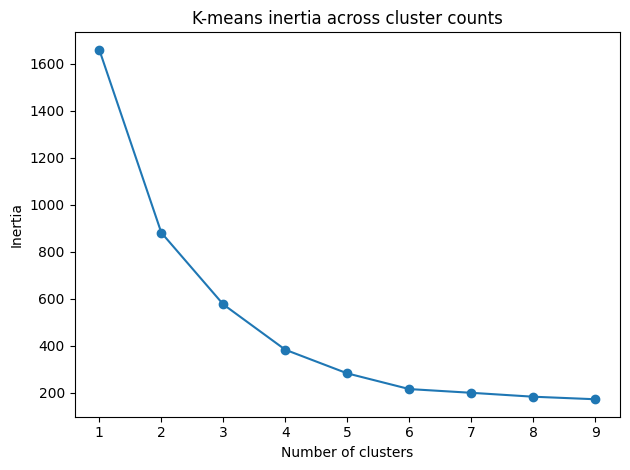

In [3]:
inertia_list = []
for i in range(1,10):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(scaled_data)
    inertia = model.inertia_
    inertia_list.append(inertia)

print(inertia_list)

plt.plot(range(1, 10), inertia_list, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("K-means inertia across cluster counts")
plt.tight_layout()
plt.show()


## 3. Fit the six-cluster model


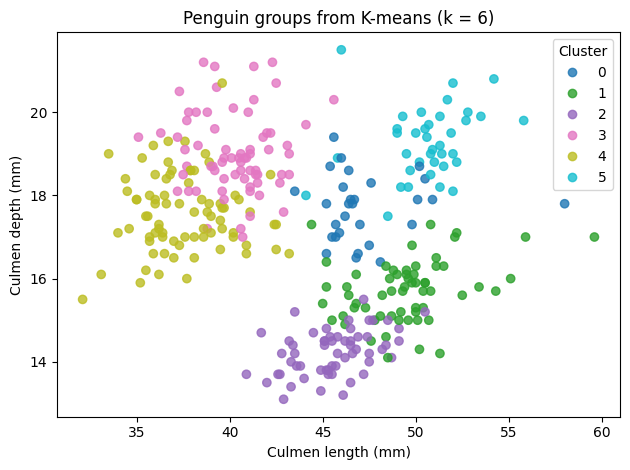

In [4]:
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
kmeans.fit(scaled_data)

scatter = plt.scatter(
    x=penguins_df["culmen_length_mm"],
    y=penguins_df["culmen_depth_mm"],
    c=kmeans.labels_,
    cmap="tab10",
    alpha=0.8,
)
plt.xlabel("Culmen length (mm)")
plt.ylabel("Culmen depth (mm)")
plt.title("Penguin groups from K-means (k = 6)")
plt.legend(*scatter.legend_elements(), title="Cluster", loc="best")
plt.tight_layout()
plt.show()


## 4. Summarize the clusters


In [5]:
numeric_columns =[
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
penguins_df["label"] = kmeans.labels_

stat_penguins =penguins_df.groupby('label')[numeric_columns].mean()
print(stat_penguins)


       culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
label                                                                   
0             47.310345        17.706897         192.758621  3569.827586
1             49.473770        15.718033         221.540984  5484.836066
2             45.563793        14.237931         212.706897  4679.741379
3             40.260870        19.026087         191.985507  4035.144928
4             37.580769        17.575641         187.666667  3363.141026
5             50.624324        19.270270         199.945946  3953.378378


## Interpretation

The six groups differ in body size and bill measurements. Since sex is included as a standardized input, it also contributes to the grouping. Cluster numbers are arbitrary identifiers and can be permuted between library versions. Without species labels or external validation, these groups should not be treated as confirmed species.
